# B1_lingkungan: Evaluasi Praktikum P1-P4 Computer Vision (SIMUTEH)
**Nama:** Rian | **NIM:** 2330511025 | **SEED:** 1025 | **Kelas:** 6A

Notebook pertama. Menyiapkan struktur folder, menulis `src/`, membangkitkan dataset (SEED 1025), menguji lingkungan, dan menjawab P1.1 sampai P1.4. **Jalankan lebih dahulu.** Urutan berikutnya: B2, B3, B4, B5.

> Angka pada teks jawaban berasal dari satu kali jalan dengan SEED 1025. Nilai KB dan PSNR deterministik; **waktu (ms)** bergantung mesin, jadi cocokkan dengan keluaran milikmu.

## Bagian 1. Lingkungan Kerja dan Formulasi Masalah

In [1]:
import os, sys
# Jalankan dari folder notebook/ di dalam repository (jalur file selalu diawali ../).
if os.path.basename(os.getcwd()) != "notebook":
    BASE = "/content/simuteh-2330511025" if os.path.exists("/content") else os.path.abspath("simuteh-2330511025")
    os.makedirs(os.path.join(BASE, "notebook"), exist_ok=True); os.chdir(os.path.join(BASE, "notebook"))
for d in ["../src", "../hasil", "../data", "../laporan"]:
    os.makedirs(d, exist_ok=True)
sys.path.append("../src")
print("Folder kerja:", os.getcwd())

Folder kerja: /tmp/repo/simuteh-2330511025/notebook


In [2]:
%%writefile ../src/buat_dataset_sintetis.py
"""buat_dataset_sintetis.py - dataset sintetis SIMUTEH (SEED = 4 digit terakhir NIM)."""
import os, csv, cv2
import numpy as np

SEED = 1025  # NIM 2330511025
N_PER_KELAS = 20
H, W = 480, 640
KELAS = ["sehat", "ringan", "berat"]
KONDISI = ["normal", "gelap", "terang", "kontras_rendah", "bayangan"]
OUT = os.path.join("data", "sintetis")
rng = np.random.default_rng(SEED)

def gambar_daun(img, mask):
    cx = int(rng.integers(260, 380)); cy = int(rng.integers(200, 280))
    ax = int(rng.integers(190, 240)); ay = int(rng.integers(95, 125))
    sudut = float(rng.uniform(-25, 25))
    hijau = np.array([rng.integers(35, 60), rng.integers(120, 150), rng.integers(45, 75)])
    cv2.ellipse(img, (cx, cy), (ax, ay), sudut, 0, 360, hijau.tolist(), -1)
    cv2.ellipse(mask, (cx, cy), (ax, ay), sudut, 0, 360, 255, -1)
    t = np.deg2rad(sudut)
    p1 = (int(cx - ax * np.cos(t)), int(cy - ax * np.sin(t)))
    p2 = (int(cx + ax * np.cos(t)), int(cy + ax * np.sin(t)))
    tulang = (hijau * 1.35).clip(0, 255).tolist()
    cv2.line(img, p1, p2, tulang, 3)
    for k in np.linspace(-0.7, 0.7, 6):
        bx, by = cx + k * ax * np.cos(t), cy + k * ax * np.sin(t)
        for arah in (-1, 1):
            ex = bx + 0.35 * ax * np.cos(t + arah * 1.0)
            ey = by + 0.35 * ax * np.sin(t + arah * 1.0)
            cv2.line(img, (int(bx), int(by)), (int(ex), int(ey)), tulang, 1)
    return mask

def gambar_bercak(img, mask_daun, mask_bercak, kelas):
    if kelas == "sehat":
        return
    n = int(rng.integers(1, 4)) if kelas == "ringan" else int(rng.integers(6, 13))
    r_min, r_maks = (3, 7) if kelas == "ringan" else (5, 14)
    ys, xs = np.where(mask_daun > 0)
    for _ in range(n):
        i = int(rng.integers(0, len(xs)))
        r = int(rng.integers(r_min, r_maks + 1))
        pusat = (int(xs[i]), int(ys[i]))
        warna = [int(rng.integers(70, 100)), int(rng.integers(165, 190)), int(rng.integers(185, 210))]
        cv2.circle(img, pusat, r + 2, (40, 80, 110), -1)
        cv2.circle(img, pusat, r, warna, -1)
        cv2.circle(mask_bercak, pusat, r + 2, 255, -1)
    mask_bercak &= mask_daun

def ganggu_cahaya(img, kondisi):
    f = img.astype(np.float32)
    if kondisi == "gelap":
        f = 255 * (f / 255) ** 2.0
    elif kondisi == "terang":
        f = 255 * (f / 255) ** 0.45
    elif kondisi == "kontras_rendah":
        f = 0.35 * f + 95
    elif kondisi == "bayangan":
        gx = np.linspace(1.15, 0.30, W, dtype=np.float32)
        f = f * gx[None, :, None]
    sigma = float(rng.uniform(6, 14))
    f = f + rng.normal(0, sigma, f.shape)
    return np.clip(f, 0, 255).astype(np.uint8)

def main():
    for sub in ["citra", "bersih", "mask_daun", "mask_bercak"]:
        os.makedirs(os.path.join(OUT, sub), exist_ok=True)
    baris = []; nomor = 0
    for kelas in KELAS:
        for j in range(N_PER_KELAS):
            nomor += 1
            latar = np.array([rng.integers(150, 190), rng.integers(170, 205), rng.integers(185, 215)])
            img = np.ones((H, W, 3), np.uint8) * latar.astype(np.uint8)
            img = cv2.add(img, rng.integers(0, 12, (H, W, 3)).astype(np.uint8))
            m_daun = np.zeros((H, W), np.uint8); m_bercak = np.zeros((H, W), np.uint8)
            gambar_daun(img, m_daun)
            gambar_bercak(img, m_daun, m_bercak, kelas)
            bersih = cv2.GaussianBlur(img, (3, 3), 0.8)
            kondisi = KONDISI[j % len(KONDISI)]
            citra = ganggu_cahaya(bersih, kondisi)
            nama = f"teh_{nomor:03d}.png"
            cv2.imwrite(os.path.join(OUT, "citra", nama), citra)
            cv2.imwrite(os.path.join(OUT, "bersih", nama), bersih)
            cv2.imwrite(os.path.join(OUT, "mask_daun", nama), m_daun)
            cv2.imwrite(os.path.join(OUT, "mask_bercak", nama), m_bercak)
            persen = 100 * (m_bercak > 0).sum() / max((m_daun > 0).sum(), 1)
            baris.append([nama, kelas, kondisi, round(persen, 2)])
    with open(os.path.join(OUT, "label.csv"), "w", newline="") as f:
        w = csv.writer(f)
        w.writerow(["nama_file", "kelas", "kondisi_cahaya", "persen_bercak"])
        w.writerows(baris)
    print(f"Selesai: {nomor} citra tersimpan di {OUT}")

if __name__ == "__main__":
    main()

Writing ../src/buat_dataset_sintetis.py


In [3]:
%%writefile ../src/utils_cv.py
"""utils_cv.py: fungsi bantu SIMUTEH."""
import cv2
import numpy as np
import matplotlib.pyplot as plt

def baca(path):
    img = cv2.imread(path)
    if img is None:
        raise FileNotFoundError(f"Citra tidak ditemukan: {path}")
    return img

def tampil(daftar, judul, baris=1, ukuran=(14, 4)):
    kolom = int(np.ceil(len(daftar) / baris))
    plt.figure(figsize=ukuran)
    for i, (im, jd) in enumerate(zip(daftar, judul)):
        plt.subplot(baris, kolom, i + 1)
        if im.ndim == 3:
            plt.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB))
        else:
            plt.imshow(im, cmap="gray", vmin=0, vmax=255)
        plt.title(jd); plt.axis("off")
    plt.tight_layout()

def kontras_bercak(kanal, mask_daun, mask_bercak):
    k = kanal.astype(np.float64)
    sehat = (mask_daun > 0) & (mask_bercak == 0)
    bercak = mask_bercak > 0
    if bercak.sum() == 0:
        return float("nan")
    return abs(k[bercak].mean() - k[sehat].mean()) / (k[sehat].std() + 1e-6)

def statistik(gray):
    return {"rerata": round(float(gray.mean()), 1),
            "simpangan_baku": round(float(gray.std()), 1),
            "min": int(gray.min()), "maks": int(gray.max()),
            "persen_gelap": round(100 * float((gray < 50).mean()), 1),
            "persen_terang": round(100 * float((gray > 205).mean()), 1)}

Writing ../src/utils_cv.py


In [4]:
%%writefile ../src/praproses.py
"""praproses.py: rangkaian praproses SIMUTEH (dipakai ulang mulai P5)."""
import json
import cv2
import numpy as np

PARAM_BAWAAN = {
    "lebar": 640, "gamma": 1.0, "clahe_clip": 2.0, "clahe_tile": 8,
    "penapis": "median", "kernel": 3, "sigma": 1.0, "tajam_k": 0.0,
}

def praproses(img_bgr, p=None):
    """Urutan: ubah ukuran -> gamma -> CLAHE kanal V -> redam derau -> tajamkan."""
    p = {**PARAM_BAWAAN, **(p or {})}
    # 1. ubah ukuran (rasio aspek tetap, INTER_AREA)
    h, w = img_bgr.shape[:2]
    if w != p["lebar"]:
        tinggi = int(round(h * p["lebar"] / w))
        img = cv2.resize(img_bgr, (p["lebar"], tinggi), interpolation=cv2.INTER_AREA)
    else:
        img = img_bgr.copy()
    # 2. koreksi gamma lewat LUT
    if p["gamma"] != 1:
        lut = np.array([255 * (i / 255) ** p["gamma"] for i in range(256)]).clip(0, 255).astype(np.uint8)
        img = cv2.LUT(img, lut)
    # 3. CLAHE hanya di kanal V (HSV) agar warna (Hue) tidak bergeser
    if p["clahe_clip"] > 0:
        hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
        clahe = cv2.createCLAHE(clipLimit=p["clahe_clip"], tileGridSize=(p["clahe_tile"], p["clahe_tile"]))
        hsv[:, :, 2] = clahe.apply(hsv[:, :, 2])
        img = cv2.cvtColor(hsv, cv2.COLOR_HSV2BGR)
    # 4. redam derau
    k = int(p["kernel"])
    if p["penapis"] == "rerata":
        img = cv2.blur(img, (k, k))
    elif p["penapis"] == "gaussian":
        img = cv2.GaussianBlur(img, (k, k), p["sigma"])
    elif p["penapis"] == "median":
        img = cv2.medianBlur(img, k)
    # 5. unsharp masking opsional
    if p["tajam_k"] > 0:
        blur = cv2.GaussianBlur(img, (5, 5), 1.0)
        img = cv2.addWeighted(img, 1 + p["tajam_k"], blur, -p["tajam_k"], 0)
    return img

def simpan_param(p, path="../hasil/param_praproses.json"):
    with open(path, "w") as f:
        json.dump({**PARAM_BAWAAN, **p}, f, indent=2)

Writing ../src/praproses.py


**Langkah 1.2: pasang pustaka dan tulis `requirements.txt`.** Di Colab pustaka ini umumnya sudah ada, perintah `pip install` memastikan sekaligus mencatat versinya.

In [5]:
!pip -q install opencv-python numpy matplotlib scikit-image pandas pillow
import importlib.metadata as md_
pustaka = ["opencv-python", "numpy", "matplotlib", "scikit-image", "pandas", "pillow"]
with open("../requirements.txt", "w") as f:
    for p in pustaka:
        f.write(f"{p}=={md_.version(p)}\n")
print(open("../requirements.txt").read())

error: externally-managed-environment

× This environment is externally managed
╰─> To install Python packages system-wide, try apt install
    python3-xyz, where xyz is the package you are trying to
    install.
    
    If you wish to install a non-Debian-packaged Python package,
    create a virtual environment using python3 -m venv path/to/venv.
    Then use path/to/venv/bin/python and path/to/venv/bin/pip. Make
    sure you have python3-full installed.
    
    If you wish to install a non-Debian packaged Python application,
    it may be easiest to use pipx install xyz, which will manage a
    virtual environment for you. Make sure you have pipx installed.
    
    See /usr/share/doc/python3.12/README.venv for more information.

note: If you believe this is a mistake, please contact your Python installation or OS distribution provider. You can override this, at the risk of breaking your Python installation or OS, by passing --break-system-packages.
hint: See PEP 668 for the detai

opencv-python==4.13.0.92
numpy==2.4.4
matplotlib==3.10.8
scikit-image==0.26.0
pandas==3.0.2
pillow==12.1.1



**Langkah 1.3: bangkitkan dataset sintetis (SEED = 1025).** Skrip dijalankan dari folder utama repository.

In [6]:
!cd .. && python src/buat_dataset_sintetis.py
import glob
print("Jumlah citra:", len(glob.glob("../data/sintetis/citra/*.png")))

Selesai: 60 citra tersimpan di data/sintetis


Jumlah citra: 60


**Langkah 1.4: Kode 1.1, uji lingkungan dan struktur larik citra.**

OpenCV 4.13.0 | NumPy 2.4.4 | scikit-image 0.26.0
shape: (480, 640, 3) dtype: uint8
min-maks: 4 236
piksel (y=100, x=200) dalam urutan BGR: [173 192 199]


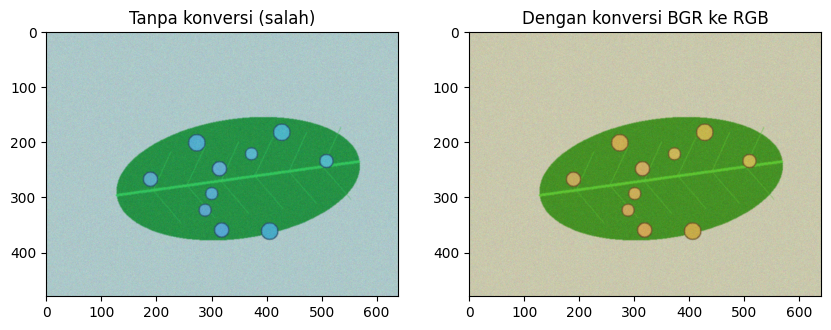

        count  mean   std   min   25%   50%   75%   max
kelas                                                  
berat    20.0  5.26  1.61  3.17  3.68  5.34  6.49  7.85
ringan   20.0  0.42  0.20  0.07  0.28  0.42  0.57  0.70
sehat    20.0  0.00  0.00  0.00  0.00  0.00  0.00  0.00


In [7]:
import cv2, numpy as np, skimage, matplotlib.pyplot as plt, pandas as pd, time
from utils_cv import baca, tampil, kontras_bercak, statistik
print("OpenCV", cv2.__version__, "| NumPy", np.__version__, "| scikit-image", skimage.__version__)
img = baca("../data/sintetis/citra/teh_041.png")
print("shape:", img.shape, "dtype:", img.dtype)
print("min-maks:", img.min(), img.max())
print("piksel (y=100, x=200) dalam urutan BGR:", img[100, 200])
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1); plt.imshow(img); plt.title("Tanpa konversi (salah)")
plt.subplot(1, 2, 2); plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB)); plt.title("Dengan konversi BGR ke RGB")
plt.savefig("../hasil/b1_bgr_rgb.png"); plt.show()
lab = pd.read_csv("../data/sintetis/label.csv")
print(lab.groupby("kelas").persen_bercak.describe().round(2))

**Langkah 1.5: Problem statement** (kerangka P1). *Ini draf; tulis ulang dengan kalimatmu sendiri sebelum dikumpulkan.*

> Bagi **petugas sortir kelompok tani teh rakyat di Kabupaten Sukabumi** yang menghadapi **penilaian mutu daun secara manual yang lama dan tidak seragam, terutama saat cahaya tidak merata dan bercak masih kecil**, kami membangun **SIMUTEH** yang menerima **foto daun teh di atas nampan sortir dari kamera telepon genggam** dan menghasilkan **kelas mutu (Sehat, Bercak Ringan, Bercak Berat) beserta persentase luas bercak**, sehingga **petugas memiliki pertimbangan yang konsisten dan cepat, sementara keputusan akhir tetap di tangan petugas**.

**Langkah 1.6: Diagram pipeline SIMUTEH enam tahap**, disimpan sebagai `hasil/b1_pipeline.png`.

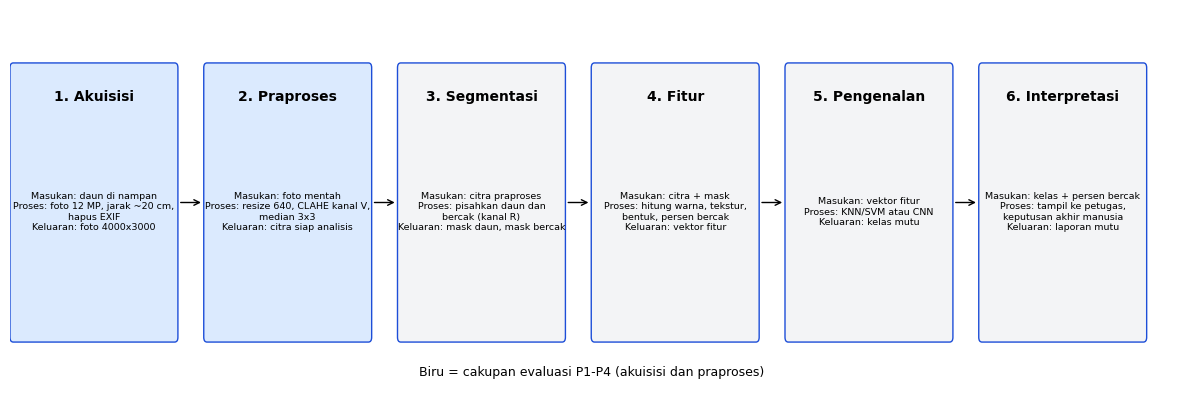

In [8]:
from matplotlib.patches import FancyBboxPatch
tahap = [
 ("1. Akuisisi", "Masukan: daun di nampan\nProses: foto 12 MP, jarak ~20 cm,\nhapus EXIF\nKeluaran: foto 4000x3000"),
 ("2. Praproses", "Masukan: foto mentah\nProses: resize 640, CLAHE kanal V,\nmedian 3x3\nKeluaran: citra siap analisis"),
 ("3. Segmentasi", "Masukan: citra praproses\nProses: pisahkan daun dan\nbercak (kanal R)\nKeluaran: mask daun, mask bercak"),
 ("4. Fitur", "Masukan: citra + mask\nProses: hitung warna, tekstur,\nbentuk, persen bercak\nKeluaran: vektor fitur"),
 ("5. Pengenalan", "Masukan: vektor fitur\nProses: KNN/SVM atau CNN\nKeluaran: kelas mutu"),
 ("6. Interpretasi", "Masukan: kelas + persen bercak\nProses: tampil ke petugas,\nkeputusan akhir manusia\nKeluaran: laporan mutu"),
]
fig, ax = plt.subplots(figsize=(15, 5)); ax.axis("off"); ax.set_xlim(0, 18); ax.set_ylim(0, 4)
for i, (j, t) in enumerate(tahap):
    x = i * 3
    ax.add_patch(FancyBboxPatch((x + 0.05, 0.6), 2.5, 2.8, boxstyle="round,pad=0.05", fc="#dbeafe" if i < 2 else "#f3f4f6", ec="#1d4ed8"))
    ax.text(x + 1.3, 3.05, j, ha="center", fontweight="bold", fontsize=10)
    ax.text(x + 1.3, 1.9, t, ha="center", va="center", fontsize=6.8)
    if i < 5: ax.annotate("", xy=(x + 3.0, 2), xytext=(x + 2.6, 2), arrowprops=dict(arrowstyle="->"))
ax.text(9, 0.2, "Biru = cakupan evaluasi P1-P4 (akuisisi dan praproses)", ha="center", fontsize=9)
plt.savefig("../hasil/b1_pipeline.png", dpi=150, bbox_inches="tight"); plt.show()

**Langkah 1.7: Tabel 6, risiko responsible computer vision SIMUTEH**

| Aspek | Risiko pada SIMUTEH | Mitigasi awal |
|---|---|---|
| Privasi citra | Foto tidak sengaja memuat wajah atau identitas petani; EXIF membocorkan lokasi kebun | Larangan wajah di bingkai; hapus EXIF sebelum disimpan; bila terlanjur, tutup wajah dengan kotak solid atau ambil ulang foto |
| Bias dan keadilan | Data sintetis hanya meniru satu jenis daun, warna latar, dan bercak bulat; kurang mewakili klon teh, cuaca, atau ponsel lain, sehingga akurasi bisa timpang antar kelompok tani | Uji pada foto nyata dari beberapa kebun dan ponsel; laporkan hasil per kondisi cahaya, bukan hanya rata-rata |
| Transparansi | Petugas tidak tahu seberapa yakin sistem dan apa yang diubah praproses | Tampilkan persentase bercak dan mask; simpan parameter praproses di JSON; nyatakan bahwa sistem alat bantu |
| Keamanan data | Foto dan label di repository publik atau perangkat hilang | Repository privat; akses terbatas kolaborator; jangan unggah data asli tanpa izin |
| Dampak sosial | Daun sehat dinilai berat merugikan harga petani; daun berat dinilai sehat merugikan pembeli dan menyebarkan penyakit; ketergantungan berlebihan pada sistem | Keputusan akhir tetap petugas; ambang konservatif; evaluasi kesalahan dua arah |
| Keterlacakan | Hasil tidak bisa diulang karena parameter, SEED, atau versi pustaka tidak tercatat | `requirements.txt`, SEED di README, `param_praproses.json`, tag `v0.1-praproses` |

**Langkah 1.8: commit** (jalankan di terminal atau sel Colab setelah repository dibuat):
```bash
git init && git add . && git commit -m "B1: setup lingkungan dan formulasi masalah"
```
Pembuatan repository GitHub `simuteh-2330511025` dan penambahan dosen sebagai kolaborator **harus kamu lakukan sendiri** di akun GitHub-mu.

### Jawaban Pertanyaan Analisis Bagian 1

**P1.1 Semantic gap.** Petugas sortir melihat sehelai daun teh hijau dengan bintik kuning pucat bertepi cokelat, lalu langsung menyimpulkan "ini terkena cacar daun". Komputer hanya menerima larik `480 x 640 x 3` bertipe `uint8` (Kode 1.1: shape `(480, 640, 3)`, dtype `uint8`). Contohnya piksel (y=100, x=200) bernilai BGR `[173 192 199]`: sekadar tiga angka 0 sampai 255, tanpa arti "daun", "nampan", atau "bercak". Jarak antara angka piksel dan makna "daun sakit" itulah semantic gap; seluruh tahap pipeline (praproses, segmentasi, fitur, pengenalan) bertugas menjembataninya.

**P1.2 Tiga sumber variasi paling mengganggu.**
1. *Pencahayaan*: kondisi gelap, terik, kontras rendah, dan bayangan (terbukti menurunkan KB pada Bagian 2). Ditangani tahap **praproses** (koreksi gamma, CLAHE).
2. *Skala/jarak pemotretan*: jarak yang berbeda mengubah ukuran bercak dalam piksel (P2.1). Ditangani tahap **akuisisi** (aturan jarak) dan sebagian oleh **fitur/geometri** (normalisasi ukuran).
3. *Derau dan latar*: derau sensor dan anyaman nampan. Ditangani tahap **praproses** (penapis median/Gaussian) dan **segmentasi** (memisahkan daun dari latar).

**P1.3 Tanpa konversi BGR ke RGB.** OpenCV menyimpan kanal berurutan B, G, R, sedangkan Matplotlib mengasumsikan R, G, B, sehingga kanal merah dan biru tertukar. Daun hijau relatif tetap hijau (kanal G tidak bertukar), tetapi bercak kuning (R dan G tinggi, B rendah) tampak kebiruan dan latar krem tampak kebiruan. Bila kesalahan terbawa ke fitur warna P9, rerata kanal R dan B, serta nilai Hue, ikut tertukar (kuning dengan Hue sekitar 25 menjadi biru). Model belajar dari fitur yang salah, atau data latih dan uji tidak konsisten, sehingga klasifikasi mutu menjadi tidak benar tanpa ada pesan galat.

**P1.4 Siapa yang diuntungkan dan dirugikan.**
- *Sehat dinilai bercak berat* (positif palsu): petani dirugikan karena daun baik dibuang atau dihargai rendah, dan kepercayaan pada alat turun.
- *Bercak berat dinilai sehat* (negatif palsu): pembeli atau pabrik menerima daun bermutu rendah, penyakit dapat menyebar bersama lot, dan reputasi kelompok tani rusak.
- Sistem yang tepat menguntungkan petugas (konsisten, cepat) dan kelompok tani (harga adil).
- Kaitan nilai: **adil** berarti kesalahan dua arah dievaluasi dan tidak membebani satu pihak (mis. petani kecil); **amanah** berarti sistem tidak mengklaim akurasi melebihi bukti, dan keputusan akhir tetap pada petugas yang bertanggung jawab.